In [1]:
from langgraph.graph import StateGraph, START, END
from langchain_groq import ChatGroq
from typing import TypedDict
from dotenv import load_dotenv

load_dotenv()

True

In [2]:
model = ChatGroq(model="openai/gpt-oss-20b")

In [3]:
class LLMState(TypedDict):
    question: str
    answer: str

In [4]:
def llm_qa(state: LLMState) -> LLMState:

    question = state['question']

    prompt = f"""You are a highly knowledgeable and helpful AI assistant. 
Please read the user's question carefully and provide an accurate, clear, and comprehensive answer. 
If the question is ambiguous, address the most likely interpretations.

Question:
\"\"\"{question}\"\"\"

Answer:
"""

    response = model.invoke(prompt).content

    state['answer'] = response

    return state

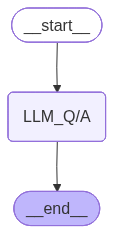

In [5]:
graph = StateGraph(LLMState)

graph.add_node('LLM_Q/A', llm_qa)

graph.add_edge(START, 'LLM_Q/A')

graph.add_edge('LLM_Q/A', END)

llm_workflow = graph.compile()

llm_workflow

In [10]:
input_state = {'question': "Who is the founder of Pakistan?"}

final_state = llm_workflow.invoke(input_state)

print(final_state)

{'question': 'Who is the founder of Pakistan?', 'answer': '**Muhammad\u202fAli\u202fJinnah** is widely regarded as the founder of Pakistan.  \n\n- **Role**: He was the leader of the All‑India Muslim League and the chief architect of the Pakistan Movement.  \n- **Title**: Often called “Quaid‑e‑Azam” (Great Leader) and “Father of the Nation.”  \n- **Key Actions**: Negotiated the Partition of British India, secured the creation of Pakistan on 14\u202fAugust\u202f1947, and served as its first Governor‑General until his death in 1948.  \n\nWhile other leaders and events (e.g., the Lahore Resolution of 1940) were also crucial, Jinnah’s leadership and vision are what make him the recognized founder of the country.'}
